# Задание 2. Распознавание цифр жестового языка (0-9)

План:
1. Загружаем фото рук из папок `0` ... `9` (название папки = цифра)
2. MobileNetV2 превращает каждое фото в 1280 чисел (признаки)
3. Обучаем 6 обычных классификаторов и LAMA на этих числах
4. Сравниваем по accuracy и F1 (macro / weighted), смотрим матрицу ошибок

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings("ignore")   # прячем жёлтые предупреждения

## 1. Данные
В папке `asl_dataset` лежат цифры (`0`-`9`) и буквы (`a`-`z`). Задание только про цифры,
поэтому буквы не берём. Метка класса - это цифра из названия папки.

In [2]:
data_dir = "asl_dataset"
digits = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

paths = []
labels = []
for d in digits:
    for name in sorted(os.listdir(data_dir + "/" + d)):
        paths.append(data_dir + "/" + d + "/" + name)
        labels.append(int(d))

y = np.array(labels)
print("Всего фото:", len(paths))
print("Фото в каждом классе:", np.bincount(y))

Всего фото: 700
Фото в каждом классе: [70 70 70 70 70 70 70 70 70 70]


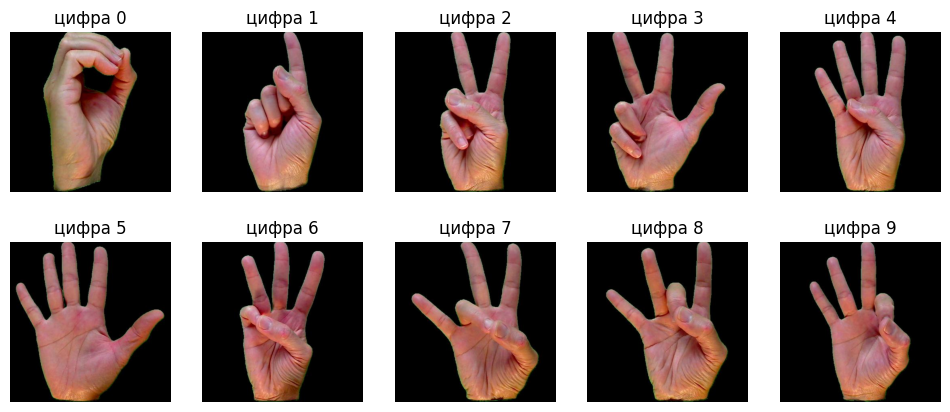

In [3]:
# по одному фото каждой цифры
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(Image.open(paths[i * 70]))
    plt.title("цифра " + str(i))
    plt.axis("off")
plt.show()

**Вывод:** 10 классов по 70 фото, всего 700. Классы сбалансированы, поэтому accuracy здесь честная метрика.

## 2. Признаки через MobileNetV2
Сеть ждёт картинки 224x224, поэтому меняем размер каждого фото. Последний слой сети убираем
(`include_top=False`), на выходе получаем 1280 чисел на фото.

In [4]:
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

if os.path.exists("features_signs.npy"):
    X = np.load("features_signs.npy")      # уже посчитано раньше
    print("Признаки взяты из файла")
else:
    images = []
    for p in paths:
        img = Image.open(p).convert("RGB").resize((224, 224))
        images.append(np.array(img))
    images = preprocess_input(np.array(images, dtype="float32"))

    model_mobilenet = MobileNetV2(weights="imagenet", include_top=False,
                                  pooling="avg", input_shape=(224, 224, 3))
    X = model_mobilenet.predict(images)
    np.save("features_signs.npy", X)       # сохраняем, чтобы не считать заново

print("Размер таблицы признаков:", X.shape)

 1/22 ━━━━━━━━━━━━━━━━━━━━ 11s 571ms/step

 2/22 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step 

 3/22 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step

 4/22 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step

 5/22 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step

...

20/22 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step

21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step

22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step

22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 138ms/step


Размер таблицы признаков: (700, 1280)


**Вывод:** каждое фото теперь строка из 1280 чисел, дальше работаем как с обычной таблицей.

## 3. Train / test и масштабирование
80% фото для обучения, 20% для проверки. `stratify=y` оставляет в обеих частях по столько же фото каждой цифры.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # учим масштаб только на train
X_test_sc = scaler.transform(X_test)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("Фото каждой цифры в тесте:", np.bincount(y_test))

Обучающая выборка: (560, 1280)
Тестовая выборка: (140, 1280)
Фото каждой цифры в тесте: [14 14 14 14 14 14 14 14 14 14]


## 4. Обычные классификаторы
Метрики для многоклассовой задачи:
- **accuracy** - доля верных ответов;
- **precision / recall / F1 macro** - считаем отдельно для каждой цифры и берём среднее (все цифры равноправны);
- **F1 weighted** - то же среднее, но цифры с большим числом фото весят больше (у нас классы равны, значения почти совпадут).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score)

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "SVC": SVC(random_state=42),
    "KNeighbors": KNeighborsClassifier(),
    "RandomForest": RandomForestClassifier(random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "MLP": MLPClassifier(max_iter=500, random_state=42),
}

rows = []
predictions = {}     # ответы каждой модели, понадобятся для матрицы ошибок
for name in models:
    model = models[name]
    model.fit(X_train_sc, y_train)
    pred = model.predict(X_test_sc)
    predictions[name] = pred
    cv_f1 = cross_val_score(model, X_train_sc, y_train, cv=5, scoring="f1_macro").mean()

    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_macro": precision_score(y_test, pred, average="macro"),
        "recall_macro": recall_score(y_test, pred, average="macro"),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "f1_weighted": f1_score(y_test, pred, average="weighted"),
        "f1_macro_cv5": cv_f1,
    })
    print(name, "- accuracy:", round(accuracy_score(y_test, pred), 3),
          " F1 macro:", round(f1_score(y_test, pred, average="macro"), 3))

LogisticRegression - accuracy: 1.0  F1 macro: 1.0


SVC - accuracy: 0.964  F1 macro: 0.965


KNeighbors - accuracy: 0.95  F1 macro: 0.95


RandomForest - accuracy: 0.979  F1 macro: 0.978


GradientBoosting - accuracy: 0.95  F1 macro: 0.95


MLP - accuracy: 0.993  F1 macro: 0.993


## 5. LAMA (LightAutoML)
Автоматическая система, сама пробует разные модели и собирает из них ансамбль.
Для 10 классов указываем задачу `multiclass`. LAMA возвращает вероятность каждой цифры,
ответом берём цифру с наибольшей вероятностью.

In [7]:
from lightautoml.automl.presets.tabular_presets import TabularAutoML
from lightautoml.tasks import Task

columns = ["f" + str(i) for i in range(X.shape[1])]
train_df = pd.DataFrame(X_train, columns=columns)
train_df["target"] = y_train
test_df = pd.DataFrame(X_test, columns=columns)

# cpu_limit=1 и n_jobs=1 - иначе LAMA падает на этом маке
automl = TabularAutoML(task=Task("multiclass"), timeout=600, cpu_limit=1,
                       reader_params={"n_jobs": 1, "random_state": 42})
automl.fit_predict(train_df, roles={"target": "target"}, verbose=0)

lama_proba = automl.predict(test_df).data          # вероятности, 10 столбцов
print("class_mapping LAMA:", automl.reader.class_mapping)

'nlp' extra dependency package 'fasttext-numpy2' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


'nlp' extra dependency package 'nltk' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


'nlp' extra dependency package 'transformers' isn't installed. Look at README.md in repo 'LightAutoML' for installation instructions.


class_mapping LAMA: None


In [8]:
# столбец -> цифра (LAMA может хранить классы в своём порядке)
mapping = automl.reader.class_mapping
if mapping is None:
    classes = np.arange(10)
else:
    classes = np.array(sorted(mapping, key=mapping.get))
lama_pred = classes[lama_proba.argmax(axis=1)]
predictions["LAMA"] = lama_pred

rows.append({
    "model": "LAMA",
    "accuracy": accuracy_score(y_test, lama_pred),
    "precision_macro": precision_score(y_test, lama_pred, average="macro"),
    "recall_macro": recall_score(y_test, lama_pred, average="macro"),
    "f1_macro": f1_score(y_test, lama_pred, average="macro"),
    "f1_weighted": f1_score(y_test, lama_pred, average="weighted"),
    "f1_macro_cv5": None,
})
print("LAMA - accuracy:", round(accuracy_score(y_test, lama_pred), 3),
      " F1 macro:", round(f1_score(y_test, lama_pred, average="macro"), 3))

LAMA - accuracy: 0.993  F1 macro: 0.993


## 6. Сравнение

In [9]:
results = pd.DataFrame(rows).sort_values("f1_macro", ascending=False)
print(results.round(3).to_string(index=False))

             model  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  f1_macro_cv5
LogisticRegression     1.000            1.000         1.000     1.000        1.000         0.987
               MLP     0.993            0.993         0.993     0.993        0.993         0.987
              LAMA     0.993            0.993         0.993     0.993        0.993           NaN
      RandomForest     0.979            0.980         0.979     0.978        0.978         0.966
               SVC     0.964            0.969         0.964     0.965        0.965         0.968
        KNeighbors     0.950            0.953         0.950     0.950        0.950         0.915
  GradientBoosting     0.950            0.951         0.950     0.950        0.950         0.926


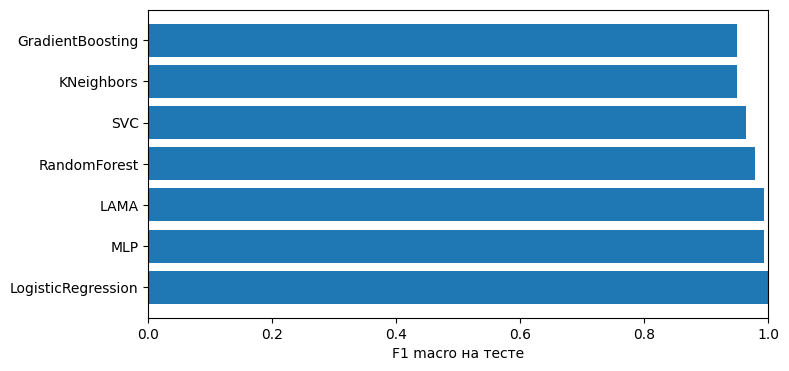

In [10]:
plt.figure(figsize=(8, 4))
plt.barh(results["model"], results["f1_macro"])
plt.xlabel("F1 macro на тесте")
plt.xlim(0, 1)
plt.show()

## 7. Подробно про лучшую модель
`classification_report` показывает precision, recall и F1 для каждой цифры отдельно,
матрица ошибок - какие цифры модель путает между собой (строка - настоящая цифра, столбец - ответ модели).

Лучшая модель: LogisticRegression

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        14
           1      1.000     1.000     1.000        14
           2      1.000     1.000     1.000        14
           3      1.000     1.000     1.000        14
           4      1.000     1.000     1.000        14
           5      1.000     1.000     1.000        14
           6      1.000     1.000     1.000        14
           7      1.000     1.000     1.000        14
           8      1.000     1.000     1.000        14
           9      1.000     1.000     1.000        14

    accuracy                          1.000       140
   macro avg      1.000     1.000     1.000       140
weighted avg      1.000     1.000     1.000       140



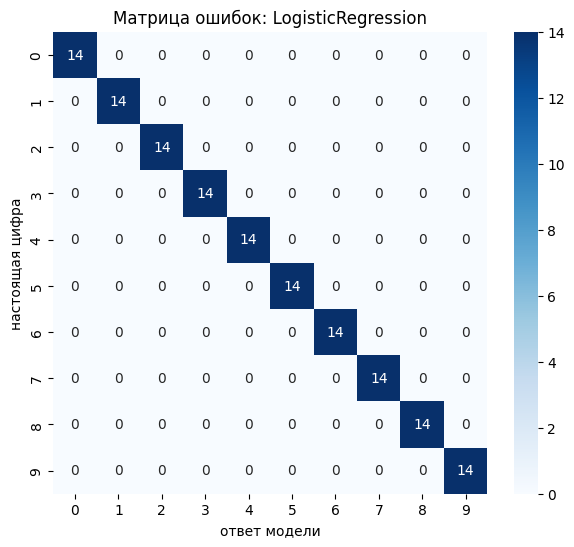

In [11]:
from sklearn.metrics import classification_report, confusion_matrix

best = results.iloc[0]["model"]
print("Лучшая модель:", best)
print()
print(classification_report(y_test, predictions[best], digits=3))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, predictions[best]), annot=True, fmt="d", cmap="Blues")
plt.xlabel("ответ модели")
plt.ylabel("настоящая цифра")
plt.title("Матрица ошибок: " + best)
plt.show()